# Hourly and Daily Demand Pattern Analysis for NYC Taxi Trips


## Libraries

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats as st

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

BLUE, ORANGE = '#2E86AB', '#F26419'
WEEKDAY_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
MONTH_ORDER = ['January', 'February', 'March', 'April', 'May', 'June']
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')

print('All libraries are ready to use.')

All libraries are ready to use.


## 1. Data Overview and Cleaning

In [98]:
raw = pd.read_csv('NYC.csv')

print(f'Rows    : {raw.shape[0]:,}')
print(f'Columns : {raw.shape[1]}')
raw.head()

Rows    : 1,458,644
Columns : 11


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.98,40.77,-73.96,40.77,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.98,40.74,-74.00,40.73,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.98,40.76,-74.01,40.71,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.01,40.72,-74.01,40.71,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.97,40.79,-73.97,40.78,N,435


In [99]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 189.2 MB


In [100]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
vendor_id,"1,458,644.00",1.53,0.50,1.00,1.00,2.00,2.00,2.00
passenger_count,"1,458,644.00",1.66,1.31,0.00,1.00,1.00,2.00,9.00
pickup_longitude,"1,458,644.00",-73.97,0.07,-121.93,-73.99,-73.98,-73.97,-61.34
pickup_latitude,"1,458,644.00",40.75,0.03,34.36,40.74,40.75,40.77,51.88
dropoff_longitude,"1,458,644.00",-73.97,0.07,-121.93,-73.99,-73.98,-73.96,-61.34
dropoff_latitude,"1,458,644.00",40.75,0.04,32.18,40.74,40.75,40.77,43.92
trip_duration,"1,458,644.00",959.49,"5,237.43",1.00,397.00,662.00,"1,075.00","3,526,282.00"


In [101]:
print(f'Total missing values : {raw.isnull().sum().sum()}')
print(f'Duplicate rows       : {raw.duplicated().sum()}')
print(f'Duplicate trip ids   : {raw["id"].duplicated().sum()}')
print()
print(raw.nunique())

Total missing values : 0
Duplicate rows       : 0
Duplicate trip ids   : 0

id                    1458644
vendor_id                   2
pickup_datetime       1380222
dropoff_datetime      1380377
passenger_count            10
pickup_longitude        23047
pickup_latitude         45245
dropoff_longitude       33821
dropoff_latitude        62519
store_and_fwd_flag          2
trip_duration            7417
dtype: int64


No missing values, no duplicated rows and no duplicated `id`. Two things in `describe()` matter for this analysis:

- `trip_duration` is in **seconds** and its maximum is 3,526,282 s (about 41 days) against a median of about 11 minutes — the column has extreme outliers and must be filtered before any average is trusted.
- `pickup_latitude` / `pickup_longitude` also contain impossible values (e.g. latitude 51.9). This analysis is purely time-based and does not use coordinates, so they are **left untouched** and not filtered.

In [102]:
df = raw.copy()
df['pickup_datetime']  = pd.to_datetime(df['pickup_datetime'],  format='%Y-%m-%d %H:%M:%S')
df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'], format='%Y-%m-%d %H:%M:%S')


In [103]:

print(f'First pickup : {df["pickup_datetime"].min()}')
print(f'Last pickup  : {df["pickup_datetime"].max()}')
print(f'Days covered : {df["pickup_datetime"].dt.normalize().nunique()}')


First pickup : 2016-01-01 00:00:17
Last pickup  : 2016-06-30 23:59:39
Days covered : 182


In [104]:

mismatch = ((df['dropoff_datetime'] - df['pickup_datetime']).dt.total_seconds() != df['trip_duration']).sum()
print(f'Rows where trip_duration != dropoff - pickup : {mismatch}')

Rows where trip_duration != dropoff - pickup : 0


`trip_duration` equals `dropoff − pickup` in every row, so the column is internally consistent. The data covers **182 days (January–June 2016) — only half a year**, so any "seasonality" finding below is a Jan–Jun pattern, not a full-year one.

In [105]:
df['trip_duration_min'] = df['trip_duration'] / 60
df['too_short'] = df['trip_duration_min'] < 1
df['too_long']  = df['trip_duration_min'] > 120
over_24h = (df['trip_duration_min'] > 1440).sum()
near_24h = df['trip_duration_min'].between(1380, 1440).sum()


In [106]:

print(f'Trips shorter than 1 minute      : {df["too_short"].sum():,} ({df["too_short"].mean()*100:.2f}%)')
print(f'Trips longer than 120 minutes    : {df["too_long"].sum():,} ({df["too_long"].mean()*100:.2f}%)')
print(f'Trips longer than 24 hours       : {over_24h:,}')
print(f'Trips lasting 23-24 hours        : {near_24h:,}')
print(f'Longest trip (minutes)           : {df["trip_duration_min"].max():,.0f}')
print()
print(df['trip_duration_min'].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(2))

Trips shorter than 1 minute      : 8,595 (0.59%)
Trips longer than 120 minutes    : 2,253 (0.15%)
Trips longer than 24 hours       : 4
Trips lasting 23-24 hours        : 1,839
Longest trip (minutes)           : 58,771

0.01       1.45
0.05       3.00
0.25       6.62
0.50      11.03
0.75      17.92
0.95      35.07
0.99      57.33
1.00   1,418.81
Name: trip_duration_min, dtype: float64


In [107]:
outlier_by_vendor = (df.groupby('vendor_id')
                       .agg(trips=('id', 'size'),
                            too_short=('too_short', 'sum'),
                            too_long=('too_long', 'sum'))
                       .reset_index())
outlier_by_vendor['too_long_share_of_all_%'] = outlier_by_vendor['too_long'] / outlier_by_vendor['too_long'].sum() * 100
outlier_by_vendor

,vendor_id,trips,too_short,too_long,too_long_share_of_all_%
0,1,678342,5095,83,3.68
1,2,780302,3500,2170,96.32


Outliers are not spread evenly across vendors: vendor 2 produced **2,170 of the 2,253** trips longer than 120 minutes (96.3%), including 1,839 trips lasting between 23 and 24 hours. A trip that lasts almost exactly one day is far more likely a meter left running than a real ride, which points to a vendor-specific recording issue. Only **4** trips exceed 24 hours (the longest is 58,771 minutes ≈ 41 days).

In [108]:
clean = df[(df['trip_duration_min'] >= 1) & (df['trip_duration_min'] <= 120)].copy()

print(f'Before cleaning    : {len(df):,}')
print(f'After cleaning     : {len(clean):,}')
print(f'Reduced row count  : {len(df) - len(clean):,} ({(len(df) - len(clean)) / len(df) * 100:.2f}%)')
print(f'Trips with 0 passengers kept : {(clean["passenger_count"] == 0).sum()}')

Before cleaning    : 1,458,644
After cleaning     : 1,447,796
Reduced row count  : 10,848 (0.74%)
Trips with 0 passengers kept : 17


In [109]:
impact = pd.DataFrame({'raw': df['trip_duration_min'].describe(),
                       'clean': clean['trip_duration_min'].describe()})
impact.loc['skew'] = [df['trip_duration_min'].skew(), clean['trip_duration_min'].skew()]
print(f'Mean change after filtering   : {(clean["trip_duration_min"].mean() / df["trip_duration_min"].mean() - 1) * 100:.1f}%')
print(f'Median change after filtering : {(clean["trip_duration_min"].median() / df["trip_duration_min"].median() - 1) * 100:.1f}%')
impact

Mean change after filtering   : -12.4%
Median change after filtering : 0.5%


,raw,clean
count,"1,458,644.00","1,447,796.00"
mean,15.99,14.01
std,87.29,10.89
min,0.02,1.00
25%,6.62,6.68
50%,11.03,11.08
75%,17.92,17.93
max,"58,771.37",119.85
skew,343.16,2.21


Filtering removed **10,848 rows (0.74%)**: 8,595 trips under 1 minute and 2,253 over 120 minutes. The impact is visible in the summary statistics:

- The **mean fell from 15.99 to 14.01 minutes (−12.4%)**, while the **median barely moved (11.03 → 11.08)**. A 0.74% slice of rows was pulling the mean up by two minutes, so the median is the safer headline number.
- Skew dropped from extreme to **2.21** — still clearly right-skewed after cleaning, which matters for the choice of statistical tests in Part 3.
- Trips with 0 passengers (17 rows after filtering, 60 before) are kept: passenger count is irrelevant to time-based demand.

In [110]:
clean['hour']        = clean['pickup_datetime'].dt.hour
clean['weekday']     = clean['pickup_datetime'].dt.dayofweek          # 0 = Monday
clean['weekday_name'] = pd.Categorical(clean['pickup_datetime'].dt.day_name(), categories=WEEKDAY_ORDER, ordered=True)
clean['month']       = clean['pickup_datetime'].dt.month
clean['month_name']  = pd.Categorical(clean['pickup_datetime'].dt.month_name(), categories=MONTH_ORDER, ordered=True)
clean['is_weekend']  = clean['weekday'] >= 5
clean['date']        = clean['pickup_datetime'].dt.normalize()


In [111]:

print(f'hour    : {clean["hour"].min()} - {clean["hour"].max()}')
print(f'weekday : {clean["weekday"].min()} - {clean["weekday"].max()}')
print(f'month   : {clean["month"].min()} - {clean["month"].max()}')
print(f'Missing in month_name / weekday_name : {clean["month_name"].isnull().sum()} / {clean["weekday_name"].isnull().sum()}')
clean[['pickup_datetime', 'hour', 'weekday_name', 'month_name', 'is_weekend', 'trip_duration_min']].head()

hour    : 0 - 23
weekday : 0 - 6
month   : 1 - 6
Missing in month_name / weekday_name : 0 / 0


,pickup_datetime,hour,weekday_name,month_name,is_weekend,trip_duration_min
0,2016-03-14 17:24:55,17,Monday,March,False,7.58
1,2016-06-12 00:43:35,0,Sunday,June,True,11.05
2,2016-01-19 11:35:24,11,Tuesday,January,False,35.40
3,2016-04-06 19:32:31,19,Wednesday,April,False,7.15
4,2016-03-26 13:30:55,13,Saturday,March,True,7.25


All derived columns are inside their expected ranges (`hour` 0–23, `weekday` 0–6, `month` 1–6) with no missing labels. From here on, every analysis uses the `clean` DataFrame.

## 2. Analysis

### 2.1 Trips by hour of day — peak and off-peak windows

In [112]:
hourly = (clean.groupby('hour')
               .agg(trips=('id', 'size'),
                    avg_duration=('trip_duration_min', 'mean'),
                    median_duration=('trip_duration_min', 'median'))
               .reset_index())

In [113]:
hourly['trips_share_%'] = hourly['trips'] / hourly['trips'].sum() * 100
hourly['busy_car_hours'] = hourly['trips'] * hourly['avg_duration'] / 60  

In [114]:
avg_hourly_trips = hourly['trips'].mean()
hourly['window'] = np.where(hourly['trips'] > 1.25 * avg_hourly_trips, 'Peak',
                   np.where(hourly['trips'] < 0.50 * avg_hourly_trips, 'Off-peak', 'Normal'))

In [115]:
for label in ['Peak', 'Off-peak']:
    hrs = hourly[hourly['window'] == label]
    print(f'{label:<9}: {hrs["hour"].min():02d}:00-{hrs["hour"].max():02d}:59 | '
          f'{hrs["trips"].sum():,} trips | {hrs["trips"].sum() / hourly["trips"].sum() * 100:.1f}% of all trips | '
          f'{len(hrs)} of 24 hours')

hourly.round(2)

Peak     : 17:00-22:59 | 502,764 trips | 34.7% of all trips | 6 of 24 hours
Off-peak : 02:00-05:59 | 78,589 trips | 5.4% of all trips | 4 of 24 hours


,hour,trips,avg_duration,median_duration,trips_share_%,busy_car_hours,window
0,0,52775,13.10,10.82,3.65,"11,521.79",Normal
1,1,38221,12.41,10.27,2.64,"7,903.40",Normal
2,2,27661,11.79,9.92,1.91,"5,434.63",Off-peak
3,3,20637,11.81,9.93,1.43,"4,061.99",Off-peak
4,4,15524,12.38,10.30,1.07,"3,203.37",Off-peak
5,5,14767,12.01,8.77,1.02,"2,955.09",Off-peak
6,6,32933,11.27,7.93,2.27,"6,183.99",Normal
7,7,55213,12.70,9.62,3.81,"11,689.81",Normal
8,8,66662,13.96,11.05,4.60,"15,513.80",Normal
9,9,67253,14.12,11.38,4.65,"15,826.90",Normal


In [116]:
peak_hours    = hourly.loc[hourly['window'] == 'Peak', 'hour']
offpeak_hours = hourly.loc[hourly['window'] == 'Off-peak', 'hour']

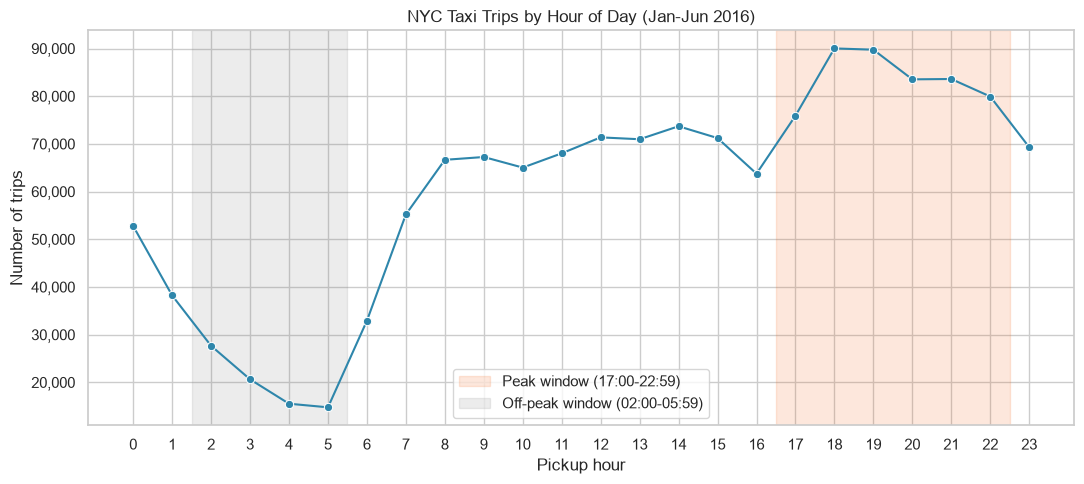

Takeaway: 18:00 is the busiest hour with 90,022 trips (6.2% of all trips), 6.1x the quietest hour (5:00, 14,767 trips).


In [117]:

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=hourly, x='hour', y='trips', marker='o', color=BLUE, ax=ax)
ax.axvspan(peak_hours.min() - 0.5, peak_hours.max() + 0.5, color=ORANGE, alpha=0.15,
           label=f'Peak window ({peak_hours.min():02d}:00-{peak_hours.max():02d}:59)')
ax.axvspan(offpeak_hours.min() - 0.5, offpeak_hours.max() + 0.5, color='grey', alpha=0.15,
           label=f'Off-peak window ({offpeak_hours.min():02d}:00-{offpeak_hours.max():02d}:59)')
ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(thousands)
ax.set_title('NYC Taxi Trips by Hour of Day (Jan-Jun 2016)')
ax.set_xlabel('Pickup hour')
ax.set_ylabel('Number of trips')
ax.legend()
plt.tight_layout()
plt.show()

top = hourly.loc[hourly['trips'].idxmax()]
low = hourly.loc[hourly['trips'].idxmin()]
print(f'Takeaway: {int(top["hour"])}:00 is the busiest hour with {top["trips"]:,.0f} trips ({top["trips_share_%"]:.1f}% of all trips), '
      f'{top["trips"] / low["trips"]:.1f}x the quietest hour ({int(low["hour"])}:00, {low["trips"]:,.0f} trips).')

Demand has two clear shapes: a **daytime plateau of about 64–74k trips per hour from 08:00 to 16:59**, then a **single evening surge peaking at 18:00–19:00** (90,022 and 89,753 trips). The six hours from 17:00 to 22:59 carry **34.7% of all trips in 25% of the day**, while the four hours from 02:00 to 05:59 carry only **5.4%**. The quietest hour is 05:00 (14,767 trips), not the middle of the night: demand bottoms out right before the morning ramp-up at 06:00–07:00.

> The evening, not the morning, is the dominant rush hour in this data.

### 2.2 Trips by day of week — weekday vs weekend

In [118]:
weekday_summary = (clean.groupby('weekday_name', observed=True)
                        .agg(trips=('id', 'size'))
                        .reset_index())

In [119]:

daily = clean.groupby('date').size().rename('trips').reset_index()
daily['weekday']      = daily['date'].dt.dayofweek
daily['weekday_name'] = pd.Categorical(daily['date'].dt.day_name(), categories=WEEKDAY_ORDER, ordered=True)
daily['month_name']   = pd.Categorical(daily['date'].dt.month_name(), categories=MONTH_ORDER, ordered=True)
daily['is_weekend']   = daily['weekday'] >= 5


In [120]:
per_day = (daily.groupby('weekday_name', observed=True)
                .agg(days=('trips', 'size'),
                     avg_trips_per_day=('trips', 'mean'),
                     median_trips_per_day=('trips', 'median'))
                .reset_index())

In [121]:
weekday_summary = weekday_summary.merge(per_day, on='weekday_name')
weekday_summary['trips_share_%'] = weekday_summary['trips'] / weekday_summary['trips'].sum() * 100
weekday_summary.round(2)

,weekday_name,trips,days,avg_trips_per_day,median_trips_per_day,trips_share_%
0,Monday,186051,26,"7,155.81","7,219.00",12.85
1,Tuesday,201318,26,"7,743.00","7,758.50",13.91
2,Wednesday,208751,26,"8,028.88","7,980.50",14.42
3,Thursday,216947,26,"8,344.12","8,361.50",14.98
4,Friday,221870,26,"8,533.46","8,621.50",15.32
5,Saturday,219190,26,"8,430.38","8,852.00",15.14
6,Sunday,193669,26,"7,448.81","7,684.50",13.38


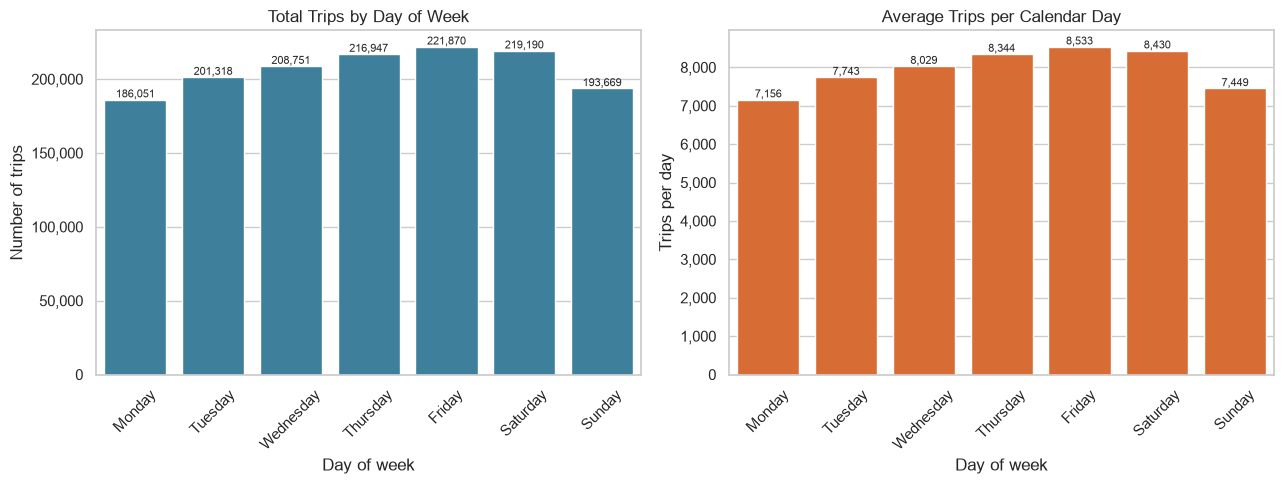

Takeaway: Friday is the busiest day (221,870 trips) and Monday the quietest (186,051); the gap is 19.3% per calendar day.


In [122]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=weekday_summary, x='weekday_name', y='trips', color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt='{:,.0f}', fontsize=8)
axes[0].yaxis.set_major_formatter(thousands)
axes[0].set_title('Total Trips by Day of Week')
axes[0].set_xlabel('Day of week')
axes[0].set_ylabel('Number of trips')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=weekday_summary, x='weekday_name', y='avg_trips_per_day', color=ORANGE, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt='{:,.0f}', fontsize=8)
axes[1].yaxis.set_major_formatter(thousands)
axes[1].set_title('Average Trips per Calendar Day')
axes[1].set_xlabel('Day of week')
axes[1].set_ylabel('Trips per day')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

best  = weekday_summary.loc[weekday_summary['trips'].idxmax()]
worst = weekday_summary.loc[weekday_summary['trips'].idxmin()]
print(f'Takeaway: {best["weekday_name"]} is the busiest day ({best["trips"]:,.0f} trips) and {worst["weekday_name"]} the quietest '
      f'({worst["trips"]:,.0f}); the gap is {(best["avg_trips_per_day"] / worst["avg_trips_per_day"] - 1) * 100:.1f}% per calendar day.')

In [123]:
we = daily.groupby('is_weekend')['trips'].agg(days='count', avg_trips_per_day='mean', median_trips_per_day='median')
we.index = ['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)']
print(f'Weekend share of all trips      : {clean["is_weekend"].mean() * 100:.1f}% (2 of 7 days = {2 / 7 * 100:.1f}%)')
print(f'Weekend vs weekday trips per day: {(we.loc["Weekend (Sat-Sun)", "avg_trips_per_day"] / we.loc["Weekday (Mon-Fri)", "avg_trips_per_day"] - 1) * 100:+.1f}%')
we

Weekend share of all trips      : 28.5% (2 of 7 days = 28.6%)
Weekend vs weekday trips per day: -0.3%


,days,avg_trips_per_day,median_trips_per_day
Weekday (Mon-Fri),130,"7,961.05","8,010.50"
Weekend (Sat-Sun),52,"7,939.60","8,085.00"


**Friday is the busiest day (221,870 trips) and Monday the quietest (186,051)**: Friday averages 8,533 trips per calendar day against 7,156 on Monday (+19.3%). Demand climbs steadily from Monday to Friday and stays high on Saturday (8,430 per day), then drops on Sunday (7,449).



The weekday-vs-weekend comparison is less obvious than the daily one: weekends hold 28.5% of trips (2 of 7 days = 28.6%) and a weekend day averages **7,940 trips against 7,961 on a weekday (−0.3%)**. Demand does not fall on weekends — it falls on **Monday and Sunday**, so the planning unit should be the individual day, not "weekday vs weekend".

### 2.3 Average trip duration by hour

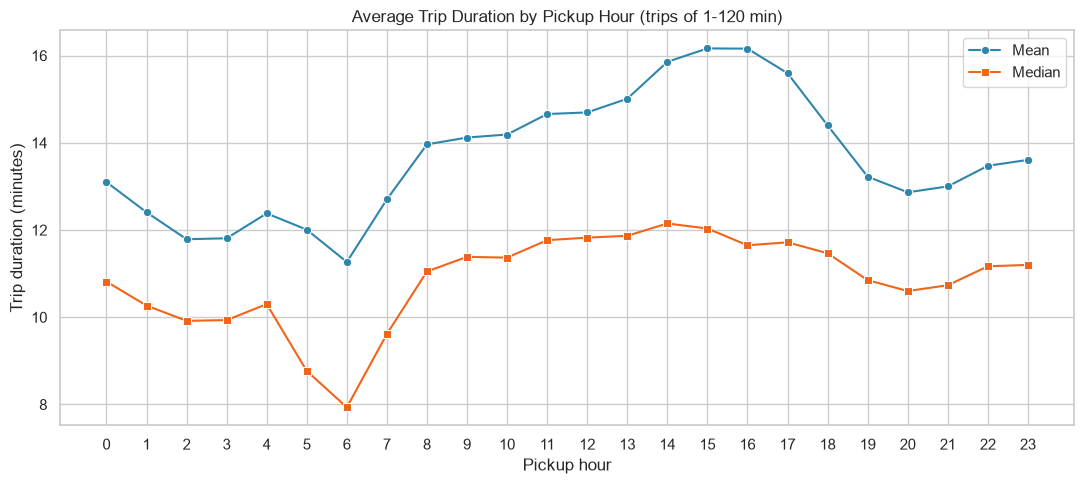

Takeaway: trips are longest at 15:00 (16.2 min) and shortest at 6:00 (11.3 min) - a 43% difference.

Top 5 hours by occupied car-hours (trips x average duration):
 hour  trips  avg_duration  busy_car_hours
   18  90022         14.40       21,602.60
   19  89753         13.20       19,779.60
   17  75910         15.60       19,731.30
   14  73697         15.90       19,476.10
   15  71223         16.20       19,187.60


In [124]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=hourly, x='hour', y='avg_duration', marker='o', color=BLUE, label='Mean', ax=ax)
sns.lineplot(data=hourly, x='hour', y='median_duration', marker='s', color=ORANGE, label='Median', ax=ax)
ax.set_xticks(range(24))
ax.set_title('Average Trip Duration by Pickup Hour (trips of 1-120 min)')
ax.set_xlabel('Pickup hour')
ax.set_ylabel('Trip duration (minutes)')
ax.legend()
plt.tight_layout()
plt.show()

longest  = hourly.loc[hourly['avg_duration'].idxmax()]
shortest = hourly.loc[hourly['avg_duration'].idxmin()]
print(f'Takeaway: trips are longest at {int(longest["hour"])}:00 ({longest["avg_duration"]:.1f} min) and shortest at {int(shortest["hour"])}:00 '
      f'({shortest["avg_duration"]:.1f} min) - a {(longest["avg_duration"] / shortest["avg_duration"] - 1) * 100:.0f}% difference.')

print()
print('Top 5 hours by occupied car-hours (trips x average duration):')
print(hourly.nlargest(5, 'busy_car_hours')[['hour', 'trips', 'avg_duration', 'busy_car_hours']].round(1).to_string(index=False))

### 2.4 Trip duration distribution

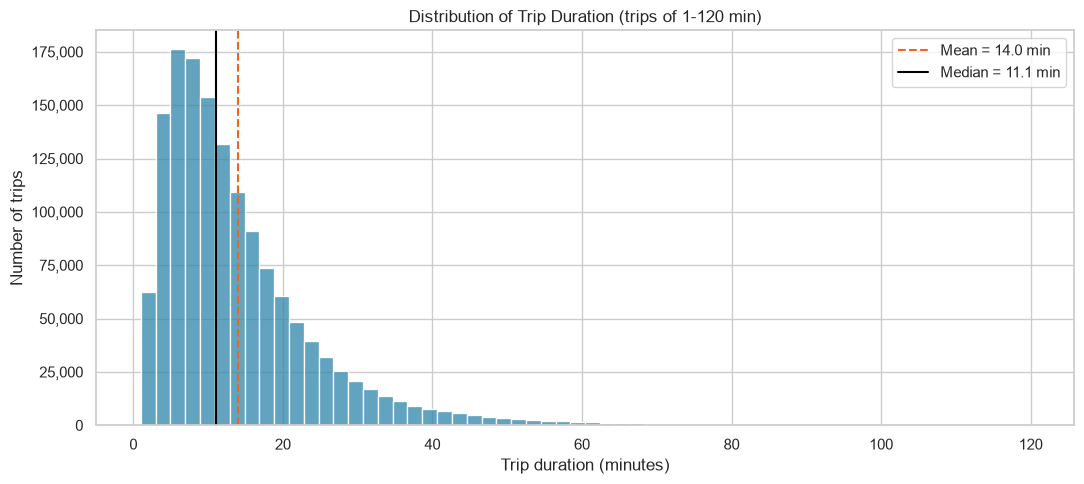

Takeaway: the distribution is right-skewed (skew = 2.21): mean 14.0 min > median 11.1 min; 75% of trips are under 17.9 min, 95% under 34.8 min, and only 0.7% exceed 60 min.


In [125]:
mean_d, median_d = clean['trip_duration_min'].mean(), clean['trip_duration_min'].median()

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(data=clean, x='trip_duration_min', bins=60, color=BLUE, ax=ax)
ax.axvline(mean_d, color=ORANGE, linestyle='--', label=f'Mean = {mean_d:.1f} min')
ax.axvline(median_d, color='black', linestyle='-', label=f'Median = {median_d:.1f} min')
ax.yaxis.set_major_formatter(thousands)
ax.set_title('Distribution of Trip Duration (trips of 1-120 min)')
ax.set_xlabel('Trip duration (minutes)')
ax.set_ylabel('Number of trips')
ax.legend()
plt.tight_layout()
plt.show()

q = clean['trip_duration_min'].quantile([0.25, 0.75, 0.95, 0.99])
print(f'Takeaway: the distribution is right-skewed (skew = {clean["trip_duration_min"].skew():.2f}): mean {mean_d:.1f} min > median {median_d:.1f} min; '
      f'75% of trips are under {q[0.75]:.1f} min, 95% under {q[0.95]:.1f} min, and only {(clean["trip_duration_min"] > 60).mean() * 100:.1f}% exceed 60 min.')

The typical trip is short: half last under **11.1 minutes** and 75% under **17.9 minutes**. A long right tail pulls the mean (14.0) above the median (11.1), which is why the median is used for headline statements and rank-based tests are used in Part 3.

### 2.5 Monthly trip count — seasonal pattern

In [126]:
monthly = (clean.groupby('month_name', observed=True)
                .agg(trips=('id', 'size'),
                     avg_duration=('trip_duration_min', 'mean'),
                     median_duration=('trip_duration_min', 'median'))
                .reset_index())

In [127]:

days_trips = (daily.groupby('month_name', observed=True)
                   .agg(days=('trips', 'size'), trips_per_day=('trips', 'mean'))
                   .reset_index())
monthly = monthly.merge(days_trips, on='month_name')

In [128]:
blizzard_days = pd.to_datetime(['2016-01-23', '2016-01-24'])
jan_no_storm = daily[(daily['month_name'] == 'January') & (~daily['date'].isin(blizzard_days))]['trips'].mean()
print(f'January trips per day: {monthly.loc[0, "trips_per_day"]:,.0f} | without 23-24 Jan: {jan_no_storm:,.0f}')
monthly.round(2)

January trips per day: 7,357 | without 23-24 Jan: 7,693


,month_name,trips,avg_duration,median_duration,days,trips_per_day
0,January,228064,13.24,10.53,31,"7,356.90"
1,February,236609,13.23,10.63,29,"8,158.93"
2,March,254306,13.69,10.93,31,"8,203.42"
3,April,249713,14.20,11.30,30,"8,323.77"
4,May,246579,14.79,11.53,31,"7,954.16"
5,June,232525,14.91,11.63,30,"7,750.83"


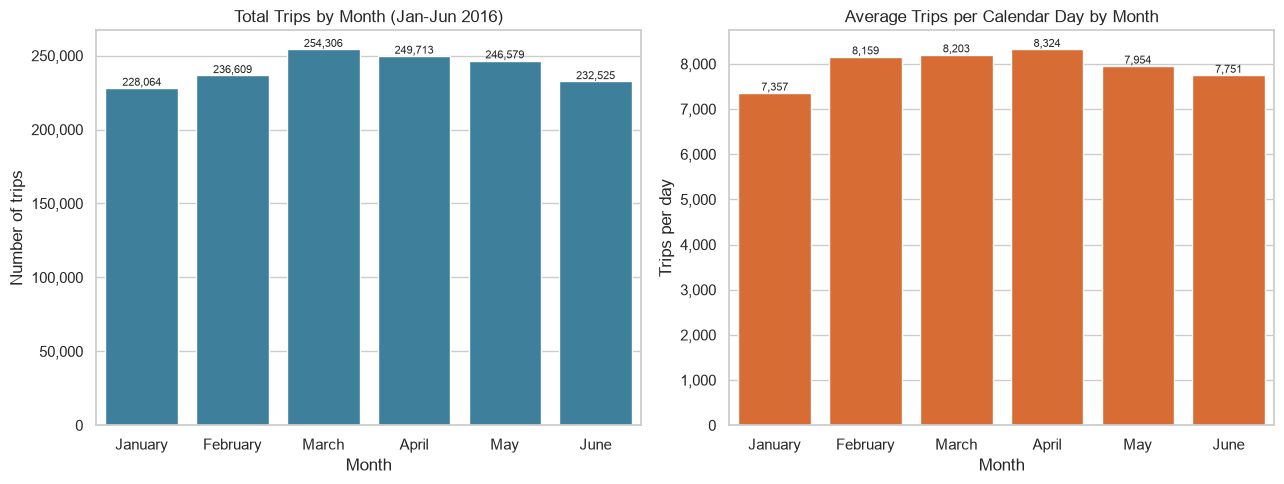

Takeaway: March has the most trips in total (254,306), but per calendar day April leads (8,324/day); the totals are distorted by month length (February has 29 days, March 31).

month_name  avg_duration  median_duration
   January         13.24            10.53
  February         13.23            10.63
     March         13.69            10.93
     April         14.20            11.30
       May         14.79            11.53
      June         14.91            11.63


In [129]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=monthly, x='month_name', y='trips', color=BLUE, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt='{:,.0f}', fontsize=8)
axes[0].yaxis.set_major_formatter(thousands)
axes[0].set_title('Total Trips by Month (Jan-Jun 2016)')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Number of trips')

sns.barplot(data=monthly, x='month_name', y='trips_per_day', color=ORANGE, ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt='{:,.0f}', fontsize=8)
axes[1].yaxis.set_major_formatter(thousands)
axes[1].set_title('Average Trips per Calendar Day by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Trips per day')

plt.tight_layout()
plt.show()

top_m = monthly.loc[monthly['trips'].idxmax()]
top_pd = monthly.loc[monthly['trips_per_day'].idxmax()]
print(f'Takeaway: {top_m["month_name"]} has the most trips in total ({top_m["trips"]:,.0f}), but per calendar day {top_pd["month_name"]} leads '
      f'({top_pd["trips_per_day"]:,.0f}/day); the totals are distorted by month length (February has 29 days, March 31).')
print()
print(monthly[['month_name', 'avg_duration', 'median_duration']].round(2).to_string(index=False))

Total counts mislead because months differ in length: **March has the most trips (254,306)** only because it has 31 days. Per calendar day, **April leads (8,324/day)**, and the pattern is *up then down*: 7,357 (Jan) → 8,159 (Feb) → 8,203 (Mar) → 8,324 (Apr) → 7,954 (May) → 7,751 (Jun). January is depressed by two storm-affected days; without 23–24 January it averages 7,693 per day, still the lowest month.

Average trip duration, in contrast, rises almost every month: **13.2 min in January–February to 14.9 min in June (+12.6%)**. April (14.2) is *not* the longest-trip month — June is. With only six months of data this is a Jan–Jun trend; it cannot be called a seasonal cycle without a full year.

### 2.6 Heatmap: hour of day × day of week (bonus)

In [130]:
heat = clean.pivot_table(index='hour', columns='weekday_name', values='id', aggfunc='count', observed=True)

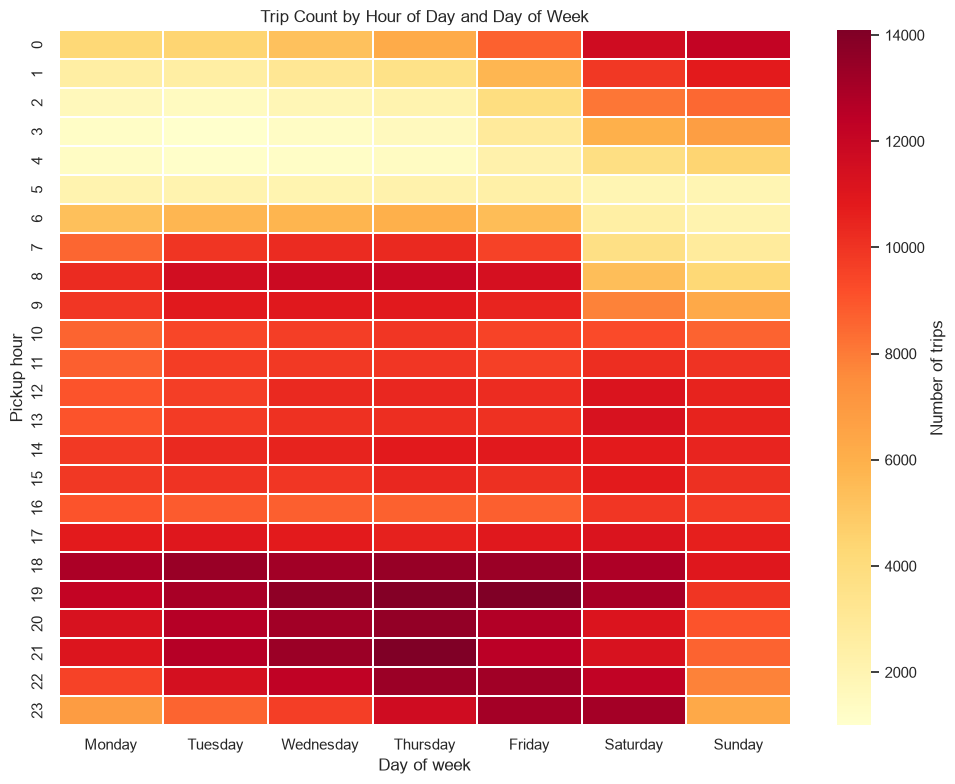

Busiest cell : Friday 19:00 with 14,087 trips
Quietest cell: Tuesday 3:00 with 1,001 trips


In [131]:

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(heat, cmap='YlOrRd', linewidths=0.3, cbar_kws={'label': 'Number of trips'}, ax=ax)
ax.set_title('Trip Count by Hour of Day and Day of Week')
ax.set_xlabel('Day of week')
ax.set_ylabel('Pickup hour')
plt.tight_layout()
plt.show()

stacked = heat.stack()
print(f'Busiest cell : {stacked.idxmax()[1]} {stacked.idxmax()[0]}:00 with {stacked.max():,} trips')
print(f'Quietest cell: {stacked.idxmin()[1]} {stacked.idxmin()[0]}:00 with {stacked.min():,} trips')

In [132]:
night = clean[clean['hour'] < 4].groupby(['date', 'is_weekend']).size().rename('trips').reset_index()
night_avg = night.groupby('is_weekend')['trips'].mean()
print(f'Takeaway: 00:00-03:59 averages {night_avg[True]:,.0f} trips on a weekend day vs {night_avg[False]:,.0f} on a weekday ({night_avg[True] / night_avg[False]:.1f}x).')

Takeaway: 00:00-03:59 averages 1,450 trips on a weekend day vs 503 on a weekday (2.9x).


The heatmap shows two different "cities". **Weekday evenings (Wed–Fri, 18:00–22:00)** are the hottest cells (Friday 19:00 = 14,087 trips is the maximum), and **the 03:00–04:00 hours on weekday nights are the coldest** (Tuesday 03:00 = 1,001 trips). On **Saturday and Sunday the heat shifts to after midnight**: the 00:00–03:59 window averages **1,450 trips on a weekend day versus 503 on a weekday (2.9x)**, and the weekend morning rush is absent.

### 2.7 Weekday vs weekend hourly profile

In [133]:
profile = clean.groupby(['is_weekend', 'hour']).size().unstack(0)
profile_share = profile / profile.sum() * 100
profile_share.columns = ['Weekday (Mon-Fri)', 'Weekend (Sat-Sun)']

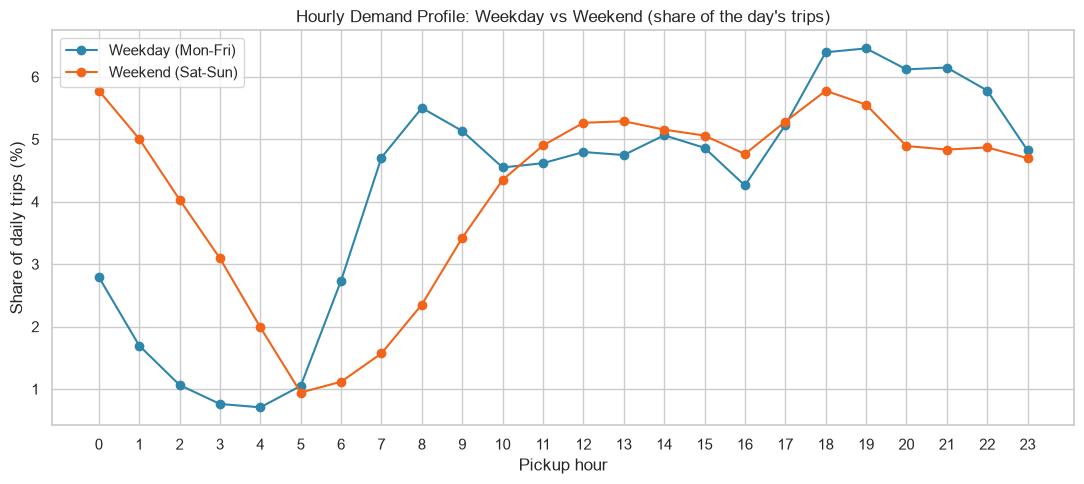

Takeaway: 07:00-09:59 holds 15.3% of weekday trips but 7.3% of weekend trips; 00:00-03:59 holds 17.9% of weekend trips vs 6.3% on weekdays.


In [134]:

fig, ax = plt.subplots(figsize=(11, 5))
profile_share.plot(ax=ax, marker='o', color=[BLUE, ORANGE])
ax.set_xticks(range(24))
ax.set_title('Hourly Demand Profile: Weekday vs Weekend (share of the day\'s trips)')
ax.set_xlabel('Pickup hour')
ax.set_ylabel('Share of daily trips (%)')
plt.tight_layout()
plt.show()

wd_morning = profile_share.loc[7:9, 'Weekday (Mon-Fri)'].sum()
we_morning = profile_share.loc[7:9, 'Weekend (Sat-Sun)'].sum()
we_night   = profile_share.loc[0:3, 'Weekend (Sat-Sun)'].sum()
wd_night   = profile_share.loc[0:3, 'Weekday (Mon-Fri)'].sum()
print(f'Takeaway: 07:00-09:59 holds {wd_morning:.1f}% of weekday trips but {we_morning:.1f}% of weekend trips; '
      f'00:00-03:59 holds {we_night:.1f}% of weekend trips vs {wd_night:.1f}% on weekdays.')

Weekdays carry a visible **morning commute shoulder at 07:00–09:59 (15.3% of the day's trips vs 7.3% on weekends)** and the evening peak. Weekends replace the commute with a **late-night tail (00:00–03:59 = 17.9% of weekend trips vs 6.3% on weekdays)** and a flatter afternoon, so one staffing template cannot serve both.

### 2.8 Vendor comparison

In [135]:
vendor_summary = (clean.groupby('vendor_id')
                       .agg(trips=('id', 'size'),
                            avg_duration=('trip_duration_min', 'mean'),
                            median_duration=('trip_duration_min', 'median'))
                       .reset_index())
vendor_summary['trips_share_%'] = vendor_summary['trips'] / vendor_summary['trips'].sum() * 100
print(vendor_summary.round(2).to_string(index=False))

 vendor_id  trips  avg_duration  median_duration  trips_share_%
         1 673164         13.93            11.05          46.50
         2 774632         14.08            11.12          53.50


In [136]:
vendor_hourly = clean.groupby(['vendor_id', 'hour'])['trip_duration_min'].mean().reset_index()

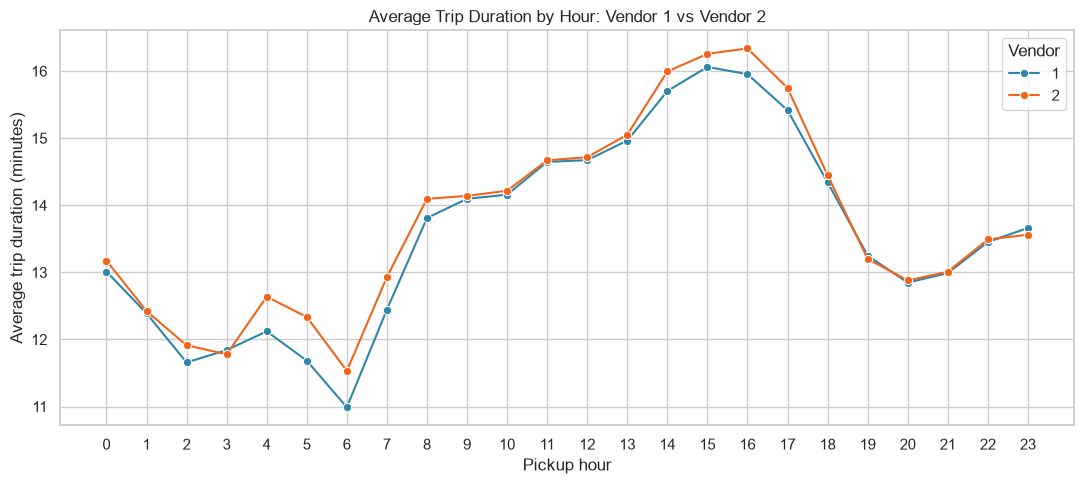

In [137]:

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=vendor_hourly, x='hour', y='trip_duration_min', hue='vendor_id', palette=[BLUE, ORANGE], marker='o', ax=ax)
ax.set_xticks(range(24))
ax.set_title('Average Trip Duration by Hour: Vendor 1 vs Vendor 2')
ax.set_xlabel('Pickup hour')
ax.set_ylabel('Average trip duration (minutes)')
ax.legend(title='Vendor')
plt.tight_layout()
plt.show()

In [138]:
gap = vendor_hourly.pivot(index='hour', columns='vendor_id', values='trip_duration_min')
gap['diff'] = gap[2] - gap[1]
print(f'Takeaway: overall mean gap is {vendor_summary.loc[1, "avg_duration"] - vendor_summary.loc[0, "avg_duration"]:.2f} min (vendor 2 longer); '
      f'the hourly gap ranges from {gap["diff"].min():+.2f} to {gap["diff"].max():+.2f} min.')

Takeaway: overall mean gap is 0.15 min (vendor 2 longer); the hourly gap ranges from -0.10 to +0.65 min.


After cleaning, the two vendors are almost identical: **vendor 2 has 53.5% of trips (774,632) and vendor 1 46.5% (673,164)**, with average durations of 14.08 and 13.93 minutes (medians 11.12 vs 11.05). The reference note's 52/48 split is close but not exact. In the *raw* data the mean gap was 3.5 minutes (17.6 vs 14.1) — that gap came entirely from the vendor-2 outliers removed in Part 1, not from real differences in trip length.

### 2.9 Daily demand series and anomalies

In [139]:
daily['rolling_7d'] = daily['trips'].rolling(7, center=True).mean()
daily['z_score'] = (daily['trips'] - daily['trips'].mean()) / daily['trips'].std()
anomalies = daily[daily['z_score'].abs() > 3]

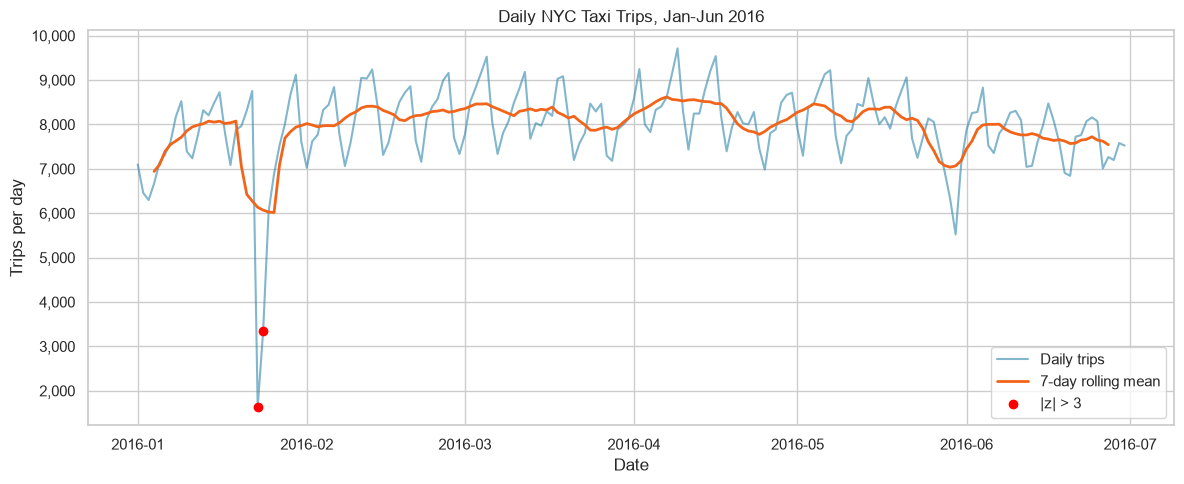

In [140]:

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily['date'], daily['trips'], color=BLUE, alpha=0.6, label='Daily trips')
ax.plot(daily['date'], daily['rolling_7d'], color=ORANGE, linewidth=2, label='7-day rolling mean')
ax.scatter(anomalies['date'], anomalies['trips'], color='red', zorder=5, label='|z| > 3')
ax.yaxis.set_major_formatter(thousands)
ax.set_title('Daily NYC Taxi Trips, Jan-Jun 2016')
ax.set_xlabel('Date')
ax.set_ylabel('Trips per day')
ax.legend()
plt.tight_layout()
plt.show()

In [141]:
avg_day = daily['trips'].mean()
print(f'Average day: {avg_day:,.0f} trips')
for _, row in daily[(daily['date'] >= '2016-01-22') & (daily['date'] <= '2016-01-26')].iterrows():
    print(f'{row["date"].date()} ({row["weekday_name"]}): {row["trips"]:,} trips ({(row["trips"] / avg_day - 1) * 100:+.1f}% vs average)')
print(f'Days with |z| > 3: {len(anomalies)} -> {[d.date().isoformat() for d in anomalies["date"]]}')

Average day: 7,955 trips
2016-01-22 (Friday): 8,754 trips (+10.0% vs average)
2016-01-23 (Saturday): 1,627 trips (-79.5% vs average)
2016-01-24 (Sunday): 3,352 trips (-57.9% vs average)
2016-01-25 (Monday): 6,034 trips (-24.1% vs average)
2016-01-26 (Tuesday): 6,888 trips (-13.4% vs average)
Days with |z| > 3: 2 -> ['2016-01-23', '2016-01-24']


Only two days out of 182 are statistical anomalies (|z| > 3): **23 January (1,627 trips, −79.5% vs the 7,955 daily average)** and **24 January (3,352, −57.9%)**. Demand recovers over three days (25 Jan: 6,034, −24.1%; 26 Jan: 6,888). The dates coincide with the January 2016 East Coast blizzard, but weather is **not in the dataset** — the link is external context, not something this data proves.

## 3. Statistical Analysis

With 1.4 million trips almost any difference is "significant", so each test below reports an effect size next to the p-value. Because trip duration is right-skewed (skew = 2.21), rank-based tests (Mann-Whitney, Kruskal-Wallis) are used instead of t-tests. Significance level: `alpha = 0.05`, adjusted with Bonferroni across all tests at the end. Demand questions (trips per day) are tested at the **day level**, because the unit that varies is a calendar day, not a trip.

In [142]:
alpha = 0.05
tests = []     # every test is collected here and summarised at the end


def rank_biserial(u_stat, n1, n2):
    """Rank-biserial correlation = P(group1 > group2) - P(group1 < group2)."""
    return 2 * u_stat / (n1 * n2) - 1


def fmt_p(p):
    return '<1e-300' if p == 0 else f'{p:.2e}'

### 3.1 Is trip duration different between vendors?

In [143]:
# Mann-Whitney because duration is right-skewed (skew = 2.21)
v1 = clean.loc[clean['vendor_id'] == 1, 'trip_duration_min']
v2 = clean.loc[clean['vendor_id'] == 2, 'trip_duration_min']

In [144]:

u = st.mannwhitneyu(v1, v2, alternative='two-sided')
r = rank_biserial(u.statistic, len(v1), len(v2))


In [145]:

print('H0: trip duration has the same distribution for vendor 1 and vendor 2')
print('H1: the distributions differ')
print(f'n1 = {len(v1):,} | n2 = {len(v2):,}')
print(f'Median: vendor 1 = {v1.median():.2f} min | vendor 2 = {v2.median():.2f} min')
print(f'Mean  : vendor 1 = {v1.mean():.2f} min | vendor 2 = {v2.mean():.2f} min')
print(f'p-value = {fmt_p(u.pvalue)} | rank-biserial r = {r:+.4f}')
print(f'Conclusion: {"Reject" if u.pvalue < alpha else "Fail to reject"} H0 - but |r| = {abs(r):.3f} is negligible (< 0.1).')
tests.append({'test': 'Mann-Whitney', 'question': 'Duration: vendor 1 vs 2', 'n': len(v1) + len(v2),
              'p_value': u.pvalue, 'effect_size': r, 'effect_type': 'rank-biserial r'})


H0: trip duration has the same distribution for vendor 1 and vendor 2
H1: the distributions differ
n1 = 673,164 | n2 = 774,632
Median: vendor 1 = 11.05 min | vendor 2 = 11.12 min
Mean  : vendor 1 = 13.93 min | vendor 2 = 14.08 min
p-value = 1.09e-07 | rank-biserial r = -0.0051
Conclusion: Reject H0 - but |r| = 0.005 is negligible (< 0.1).


In [146]:

# Robustness: the same test on the raw data with outliers
raw1 = df.loc[df['vendor_id'] == 1, 'trip_duration_min']
raw2 = df.loc[df['vendor_id'] == 2, 'trip_duration_min']
u_raw = st.mannwhitneyu(raw1, raw2, alternative='two-sided')
print()
print(f'Robustness (raw data): mean gap = {raw2.mean() - raw1.mean():.2f} min vs {v2.mean() - v1.mean():.2f} min after cleaning; '
      f'rank-biserial r = {rank_biserial(u_raw.statistic, len(raw1), len(raw2)):+.4f}')


Robustness (raw data): mean gap = 3.55 min vs 0.15 min after cleaning; rank-biserial r = -0.0107


The difference is statistically significant (n is huge) but **practically nil**: medians differ by 0.07 minutes and the rank-biserial effect is −0.005. The raw-data mean gap (3.5 min) was an outlier artefact. Vendors can be treated as equivalent for duration-based planning. This is an association in the data; it says nothing about driver or vehicle quality.

### 3.2 Is trip duration different on weekends?

In [147]:
wk  = clean.loc[~clean['is_weekend'], 'trip_duration_min']
wke = clean.loc[clean['is_weekend'], 'trip_duration_min']


In [148]:

u = st.mannwhitneyu(wk, wke, alternative='two-sided')
r = rank_biserial(u.statistic, len(wk), len(wke))


In [149]:

print('H0: weekday and weekend trips have the same duration distribution')
print('H1: the distributions differ')
print(f'n weekday = {len(wk):,} | n weekend = {len(wke):,}')
print(f'Median: weekday = {wk.median():.2f} min | weekend = {wke.median():.2f} min')
print(f'Mean  : weekday = {wk.mean():.2f} min | weekend = {wke.mean():.2f} min ({(wke.mean() / wk.mean() - 1) * 100:+.1f}%)')
print(f'p-value = {fmt_p(u.pvalue)} | rank-biserial r = {r:+.4f}')
print(f'Conclusion: {"Reject" if u.pvalue < alpha else "Fail to reject"} H0 - effect is {"small" if abs(r) >= 0.1 else "negligible"} (|r| = {abs(r):.3f}).')
tests.append({'test': 'Mann-Whitney', 'question': 'Duration: weekday vs weekend', 'n': len(wk) + len(wke),
              'p_value': u.pvalue, 'effect_size': r, 'effect_type': 'rank-biserial r'})

H0: weekday and weekend trips have the same duration distribution
H1: the distributions differ
n weekday = 1,034,937 | n weekend = 412,859
Median: weekday = 11.38 min | weekend = 10.38 min
Mean  : weekday = 14.45 min | weekend = 12.91 min (-10.7%)
p-value = <1e-300 | rank-biserial r = +0.0732
Conclusion: Reject H0 - effect is negligible (|r| = 0.073).


Weekend trips are about **1.5 minutes (10.7%) shorter on average** (12.9 vs 14.5), and the difference is highly significant, but the rank effect is below 0.1 — a **negligible-to-small shift** in the typical trip. A plausible reason is lighter weekend traffic, but traffic is not measured here, so this is an **assumption**.

### 3.3 Does trip duration change across months?

In [150]:
month_groups = [g['trip_duration_min'].values for _, g in clean.groupby('month')]
h_stat, p_val = st.kruskal(*month_groups)
epsilon_sq = h_stat / (len(clean) - 1)     # epsilon-squared effect size for Kruskal-Wallis


In [151]:

print('H0: trip duration has the same distribution in every month')
print('H1: at least one month differs')
print(f'n = {len(clean):,} | H = {h_stat:,.1f} | p-value = {fmt_p(p_val)} | epsilon-squared = {epsilon_sq:.4f}')
print('Median duration by month (min):')
print(clean.groupby('month_name', observed=True)['trip_duration_min'].median().round(2).to_string())
print(f'Conclusion: {"Reject" if p_val < alpha else "Fail to reject"} H0 - month explains {epsilon_sq * 100:.2f}% of rank variance (negligible).')
tests.append({'test': 'Kruskal-Wallis', 'question': 'Duration across 6 months', 'n': len(clean),
              'p_value': p_val, 'effect_size': epsilon_sq, 'effect_type': 'epsilon-squared'})

H0: trip duration has the same distribution in every month
H1: at least one month differs
n = 1,447,796 | H = 3,821.9 | p-value = <1e-300 | epsilon-squared = 0.0026
Median duration by month (min):
month_name
January    10.53
February   10.63
March      10.93
April      11.30
May        11.53
June       11.63
Conclusion: Reject H0 - month explains 0.26% of rank variance (negligible).


Month differs significantly, yet explains only **0.26%** of the variation in rank — the upward trend from 13.2 to 14.9 minutes is real but small relative to the spread between individual trips. It is a hypothesis worth testing with a full year (and weather/traffic data), not an established seasonal effect.

### 3.4 Does trip duration change across hours?

In [152]:
hour_groups = [g['trip_duration_min'].values for _, g in clean.groupby('hour')]
h_stat, p_val = st.kruskal(*hour_groups)
epsilon_sq = h_stat / (len(clean) - 1)


In [153]:

print('H0: trip duration has the same distribution in every pickup hour')
print('H1: at least one hour differs')
print(f'n = {len(clean):,} | H = {h_stat:,.1f} | p-value = {fmt_p(p_val)} | epsilon-squared = {epsilon_sq:.4f}')
print(f'Conclusion: {"Reject" if p_val < alpha else "Fail to reject"} H0 - hour explains {epsilon_sq * 100:.2f}% of rank variance (small).')
tests.append({'test': 'Kruskal-Wallis', 'question': 'Duration across 24 hours', 'n': len(clean),
              'p_value': p_val, 'effect_size': epsilon_sq, 'effect_type': 'epsilon-squared'})

H0: trip duration has the same distribution in every pickup hour
H1: at least one hour differs
n = 1,447,796 | H = 15,522.9 | p-value = <1e-300 | epsilon-squared = 0.0107
Conclusion: Reject H0 - hour explains 1.07% of rank variance (small).


Hour of day is the strongest duration driver tested so far (**1.1% of rank variance**), about four times the month effect, but still small: most of the variation in trip length comes from where people travel, which this dataset-level view does not capture.

### 3.5 Does the vendor mix change by hour?

In [154]:
ct = pd.crosstab(clean['hour'], clean['vendor_id'])
chi2, p_val, dof, _ = st.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
share_v2 = ct[2] / ct.sum(axis=1) * 100


In [155]:

print('H0: vendor share is independent of pickup hour')
print('H1: vendor share depends on pickup hour')
print(f'n = {ct.values.sum():,} | chi2 = {chi2:,.1f} | dof = {dof} | p-value = {fmt_p(p_val)} | Cramer V = {cramers_v:.4f}')
print(f'Vendor 2 share by hour: min {share_v2.min():.1f}% (at {share_v2.idxmin()}:00) - max {share_v2.max():.1f}% (at {share_v2.idxmax()}:00)')
print(f'Conclusion: {"Reject" if p_val < alpha else "Fail to reject"} H0 - V = {cramers_v:.3f} is negligible (< 0.1).')
tests.append({'test': 'Chi-square', 'question': 'Vendor share by hour', 'n': int(ct.values.sum()),
              'p_value': p_val, 'effect_size': cramers_v, 'effect_type': "Cramer's V"})

H0: vendor share is independent of pickup hour
H1: vendor share depends on pickup hour
n = 1,447,796 | chi2 = 578.9 | dof = 23 | p-value = 1.19e-107 | Cramer V = 0.0200
Vendor 2 share by hour: min 49.6% (at 5:00) - max 54.5% (at 10:00)
Conclusion: Reject H0 - V = 0.020 is negligible (< 0.1).


Vendor 2's share moves only between **49.6% (05:00) and 54.5%** across the day (Cramér's V = 0.02). Neither vendor dominates a particular time window, so vendor does not need to be a planning dimension.

### 3.6 Is the busiest hour also the slowest hour?

In [156]:
rho, p_val = st.spearmanr(hourly['trips'], hourly['avg_duration'])


In [157]:

print('H0: no monotonic relationship between hourly trip count and hourly average duration')
print('H1: a monotonic relationship exists')
print(f'n = {len(hourly)} hours | Spearman rho = {rho:.3f} | p-value = {fmt_p(p_val)}')
print(f'Conclusion: {"Reject" if p_val < alpha else "Fail to reject"} H0 - moderate positive association.')
print('Correlation is not causation: busier hours are not shown to *cause* longer trips; time of day drives both.')
tests.append({'test': 'Spearman', 'question': 'Hourly trips vs hourly avg duration', 'n': len(hourly),
              'p_value': p_val, 'effect_size': rho, 'effect_type': 'Spearman rho'})

H0: no monotonic relationship between hourly trip count and hourly average duration
H1: a monotonic relationship exists
n = 24 hours | Spearman rho = 0.551 | p-value = 5.23e-03
Conclusion: Reject H0 - moderate positive association.
Correlation is not causation: busier hours are not shown to *cause* longer trips; time of day drives both.


Across the 24 hours, busier hours tend to have longer trips (ρ = 0.55) — but the evening peak (18:00–19:00) is an exception, with shorter-than-afternoon trips. With n = 24 and a non-linear pattern this is a weak guide: **time of day is probably driving both measures** (a confounder), so it should not be read as "more demand makes trips longer".

### 3.7 Do weekdays really differ in daily demand?

In [158]:
day_groups = [g['trips'].values for _, g in daily.groupby('weekday')]
h_stat, p_val = st.kruskal(*day_groups)
epsilon_sq = h_stat / (len(daily) - 1)


In [159]:

print('H0: daily trip counts have the same distribution on every day of the week')
print('H1: at least one weekday differs')
print(f'n = {len(daily)} days | H = {h_stat:.1f} | p-value = {fmt_p(p_val)} | epsilon-squared = {epsilon_sq:.3f}')


H0: daily trip counts have the same distribution on every day of the week
H1: at least one weekday differs
n = 182 days | H = 94.3 | p-value = 3.82e-18 | epsilon-squared = 0.521


In [160]:

# Robustness: remove the two storm days
no_storm = daily[~daily['date'].isin(blizzard_days)]
h2, p2 = st.kruskal(*[g['trips'].values for _, g in no_storm.groupby('weekday')])
print(f'Robustness (without 23-24 Jan): H = {h2:.1f} | p-value = {fmt_p(p2)} | epsilon-squared = {h2 / (len(no_storm) - 1):.3f}')


Robustness (without 23-24 Jan): H = 98.7 | p-value = 4.71e-19 | epsilon-squared = 0.551


In [161]:

# Monday vs Friday, day level
mon = daily.loc[daily['weekday'] == 0, 'trips']
fri = daily.loc[daily['weekday'] == 4, 'trips']
u = st.mannwhitneyu(mon, fri, alternative='two-sided')
r = rank_biserial(u.statistic, len(mon), len(fri))
print()
print(f'Monday vs Friday daily trips: median {mon.median():,.0f} vs {fri.median():,.0f} | n = {len(mon)} vs {len(fri)} | p-value = {fmt_p(u.pvalue)} | r = {r:+.3f}')
print(f'Conclusion: {"Reject" if p_val < alpha else "Fail to reject"} H0 - the day-of-week pattern is real and large (epsilon-squared = {epsilon_sq:.2f}), and survives removing the storm days.')
tests.append({'test': 'Kruskal-Wallis', 'question': 'Daily trips across weekdays', 'n': len(daily),
              'p_value': p_val, 'effect_size': epsilon_sq, 'effect_type': 'epsilon-squared'})
tests.append({'test': 'Mann-Whitney', 'question': 'Daily trips: Monday vs Friday', 'n': len(mon) + len(fri),
              'p_value': u.pvalue, 'effect_size': r, 'effect_type': 'rank-biserial r'})


Monday vs Friday daily trips: median 7,219 vs 8,622 | n = 26 vs 26 | p-value = 7.73e-09 | r = -0.935
Conclusion: Reject H0 - the day-of-week pattern is real and large (epsilon-squared = 0.52), and survives removing the storm days.


This is the one pattern in the analysis that is both significant **and large**: weekday explains about **52%** of the rank variance in daily trips, Monday's median is clearly below Friday's, and the result is unchanged without the storm days. Mondays being lower and Fridays higher is a stable feature of these six months, not noise.

In [162]:
results = pd.DataFrame(tests)
alpha_adj = alpha / len(results)
results['p_value_text'] = results['p_value'].apply(fmt_p)
results['significant_bonferroni'] = results['p_value'] < alpha_adj
print(f'Bonferroni-adjusted alpha = {alpha:.2f} / {len(results)} = {alpha_adj:.4f}')
results[['test', 'question', 'n', 'p_value_text', 'effect_type', 'effect_size', 'significant_bonferroni']].round(4)

Bonferroni-adjusted alpha = 0.05 / 8 = 0.0063


,test,question,n,p_value_text,effect_type,effect_size,significant_bonferroni
0,Mann-Whitney,Duration: vendor 1 vs 2,1447796,1.09e-07,rank-biserial r,-0.01,True
1,Mann-Whitney,Duration: weekday vs weekend,1447796,<1e-300,rank-biserial r,0.07,True
2,Kruskal-Wallis,Duration across 6 months,1447796,<1e-300,epsilon-squared,0.00,True
3,Kruskal-Wallis,Duration across 24 hours,1447796,<1e-300,epsilon-squared,0.01,True
4,Chi-square,Vendor share by hour,1447796,1.19e-107,Cramer's V,0.02,True
5,Spearman,Hourly trips vs hourly avg duration,24,5.23e-03,Spearman rho,0.55,True
6,Kruskal-Wallis,Daily trips across weekdays,182,3.82e-18,epsilon-squared,0.52,True
7,Mann-Whitney,Daily trips: Monday vs Friday,52,7.73e-09,rank-biserial r,-0.93,True


All eight tests survive Bonferroni correction (α = 0.05 / 8 = 0.0063), but only the two day-level demand tests have large effects: **weekday vs daily trips (ε² = 0.52)** and **Monday vs Friday (r = −0.93)**. Hour vs duration (ε² = 0.011) is small, and the vendor, month, weekend and vendor-by-hour differences are statistically significant yet negligible — **significant is not the same as useful**. The hourly Spearman result (ρ = 0.55, p = 0.005) rests on only 24 points and clears the corrected threshold narrowly.

## 4. Final Summary

### Key Findings


1. **Evening is the main rush hour.** 18:00 is the busiest hour (90,022 trips, 6.2% of all trips, 6.1x the quietest hour 05:00 at 14,767); hours 17:00–22:59 carry 34.7% of trips.
2. **Quietest window is 02:00–05:59:** 5.4% of trips in 4 of 24 hours.
3. **Friday is the busiest day, Monday the quietest:** 8,533 vs 7,156 trips per calendar day (+19.3%); the pattern is significant with a large effect (ε² = 0.52) and holds without storm days.
4. **Weekend days are not quieter than weekdays** (7,940 vs 7,961 trips per day); Sunday and Monday are the low days. Weekends shift demand from the 07:00–09:59 commute to the 00:00–03:59 night (1,450 vs 503 trips per day, 2.9x).
5. **Trips are longest in the afternoon, not at the peak:** 16.2 min mean at 15:00–16:59 vs 14.4 min at 18:00; the median trip is 11.1 min (mean 14.0, skew 2.21).
6. **Monthly counts mislead:** March is highest in total (254,306), April per calendar day (8,324/day). Average trip duration drifts up from 13.2 min (Jan–Feb) to 14.9 min (Jun), but month explains only 0.26% of rank variance.
7. **Two extreme days:** 23–24 January had −79.5% and −57.9% vs the average day (only |z| > 3 days).
8. **Vendors are equivalent after cleaning:** 53.5% vs 46.5% of trips, 14.08 vs 13.93 min, rank effect −0.005. The raw 3.5-min gap was caused by vendor-2 outliers (96.3% of >120-minute trips).



### Operational Insights for Fleet Management



**Insight 1 — Put the most cars on the road from 17:00 to 23:00**
**FACT:** 17:00–22:59 = 502,764 trips (34.7%); 18:00 and 19:00 together = 12.4% of all trips.
**ACTION:** Schedule shift starts so maximum fleet strength is reached by 17:00 and is held until 23:00; avoid shift changes between 17:00 and 20:00.
**CONFIDENCE:** High (182 days, 1.4M trips). Limitation: only completed pickups are observed, so unmet demand in the evening peak cannot be measured.


**Insight 2 — Plan by day of week, not "weekday vs weekend"**
**FACT:** Friday 8,533, Saturday 8,430, Monday 7,156 and Sunday 7,449 trips per day; weekend per-day average (7,940) ≈ weekday (7,961).
**ACTION:** Schedule maintenance and driver days off on Monday (and Sunday); add capacity Thursday to Saturday. Add late-night (00:00–03:59) cover on Friday/Saturday nights, where demand is 2.9x the weekday night level.
**CONFIDENCE:** High for the pattern (stable with 26 observations per weekday, survives removing storm days); Medium for causes, which are not in the data.


**Insight 3 — Do not release cars after the morning rush: afternoon trips keep cars busy**
**FACT:** The longest trips start 14:00–16:59 (up to 16.2 min mean). By occupied car-hours, 14:00, 15:00 and 17:00 reach 89–91% of the 18:00 peak while having 16–21% fewer trips.
**ACTION:** Size afternoon capacity on occupied car-time, not trip count; treat 14:00–22:59 as one continuous high-load block with a short dip at 16:00.
**CONFIDENCE:** Medium — occupied time is derived from average durations; pickup location (which could explain trip length) is not analysed.



**Insight 4 — Prepare a severe-weather playbook**
**FACT:** On 23 January demand fell to 1,627 trips (−79.5%) and on 24 January to 3,352 (−57.9%); it took until 26 January to return to within 14% of average (6,888, −13.4%).
**ASSUMPTION:** The drop coincides with the January 2016 blizzard; weather is not in the dataset.
**ACTION:** Define a weather trigger that scales the fleet down for the event and recalls drivers ahead of the 2–3 day recovery; exclude such days from baseline demand forecasts (January average rises from 7,357 to 7,693 per day without them).
**CONFIDENCE:** Medium — the cause is external to the data; adding weather data would confirm it.


### Recommendations


- **Scheduling:** Stagger shifts around the 17:00–23:00 peak; Monday/Sunday lighter rosters; weekend night cover.
- **Capacity:** Plan on occupied car-hours, not trip counts alone.
- **Data quality:** Flag any trip longer than 120 minutes or shorter than 1 minute at source; investigate vendor 2's 1,839 trips lasting 23–24 hours (96.3% of all >120-min trips come from vendor 2).
- **Next analysis:** Add pickup zones to see where the evening peak and afternoon long trips occur; add weather data; extend to a full year.
